# Oil products demand — 01 Data pipeline: naphtha, Korea and Japan

**Purpose.** Take two public sources from their raw files to one point-in-time modelling dataset per country: naphtha demand in Korea and in Japan, and the one physical indicator fed to the model, the price Japan pays for propane against naphtha. Show for every variable where it comes from, how it was processed and from when it could legitimately be used. `02_model_naphtha.ipynb` only reads the tables this pipeline writes.

**Run order.** `python -m src.download jodi customs` (optional, refreshes the raw files) → `01_data_jet.ipynb` → this notebook → `python -m src.model` (the backtests, about an hour) → `02_model_naphtha.ipynb`. The two build cells below are the same as `python -m src.sql` and `python -m src.data`.

| Step | Where | Output |
|---|---|---|
| Ingestion | `src/download.py` | `data/KR_JP_naphtha/jodi.csv`, `customs.csv`, `customs_releases.csv` |
| Raw layer | `src/sql.py` | DuckDB table `raw`: every observation, every vintage seen |
| Clean layer | `src/sql.py` | DuckDB tables `demand`, `predictors`, `imports`, `catalog` |
| Alignment | `src/data.py` | DuckDB table `panel`, read by `src/model.py` and notebook 02 |

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

from src import config as c, data, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})
PRODUCTS = ["naphtha_kr", "naphtha_jp"]

## 1. Ingestion: raw files into DuckDB

`sql.build()` appends to `raw` whatever the files hold that the table does not: new observations and revised values, each stamped with `ingested_at`, the time its file was downloaded. Nothing is ever updated or deleted, so the load is idempotent and a revision is kept next to the value it replaces. It loads the files of both products; the jet notebook ran it first.

In [2]:
sql.build()

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
      0 rows added to raw from KR_JP_naphtha/jodi.csv
      0 rows added to raw from KR_JP_naphtha/customs.csv


In [3]:
sql.build()  # a second run adds nothing

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
      0 rows added to raw from KR_JP_naphtha/jodi.csv
      0 rows added to raw from KR_JP_naphtha/customs.csv


In [4]:
# what entered from the naphtha files, and when
sql.query("""
    SELECT file, CAST(MAX(ingested_at) AS DATE) AS ingested, COUNT(DISTINCT series) AS series, COUNT(*) AS observations,
           MIN(obs_date) AS first_date, MAX(obs_date) AS last_date
    FROM raw WHERE file LIKE 'KR_JP_naphtha/%' GROUP BY 1 ORDER BY 1
""")

,file,ingested,series,observations,first_date,last_date
0,KR_JP_naphtha/customs.csv,2026-11-19,368,13376,2009-01-01,2026-09-01
1,KR_JP_naphtha/jodi.csv,2026-11-19,9,2253,2002-01-01,2026-09-01


## 2. Sources and conventions

`catalog` is the data dictionary, stored next to the data. The publication lag is the one number the model depends on; it lives in `config.py` and is added here.

In [5]:
catalog = sql.query("SELECT * FROM catalog WHERE product LIKE 'naphtha%'")
catalog["lag_months"] = catalog["variable"].map(c.LAG).fillna(catalog["product"].map(c.DEMAND_LAG).where(catalog["variable"] == "demand"))
catalog[["product", "variable", "source", "source_id", "definition", "unit", "release", "lag_months"]]

,product,variable,source,source_id,definition,unit,release,lag_months
0,naphtha_kr,demand,JODI-Oil World Database (secondary),NAPHTHA TOTDEMO KBD,Korea total naphtha demand,kb/d,around the 20th of the second month after,2.00
1,naphtha_jp,demand,JODI-Oil World Database (secondary),NAPHTHA TOTDEMO KBD,Japan total naphtha demand,kb/d,around the 20th of the second month after,2.00
2,naphtha_kr,lpg,JODI-Oil World Database (secondary),LPG TOTDEMO KBD,Korea total LPG demand (context only),kb/d,around the 20th of the second month after,NaN
3,naphtha_jp,lpg,JODI-Oil World Database (secondary),LPG TOTDEMO KBD,Japan total LPG demand (context only),kb/d,around the 20th of the second month after,NaN
4,naphtha_kr,propane_naphtha,Japan Ministry of Finance trade statistics via e-Stat,2711.12 / 2710.12-181,CIF unit value of propane imports over that of naphtha imports (Japan),ratio,end of the following month (9-digit preliminary),1.00
5,naphtha_jp,propane_naphtha,Japan Ministry of Finance trade statistics via e-Stat,2711.12 / 2710.12-181,CIF unit value of propane imports over that of naphtha imports (Japan),ratio,end of the following month (9-digit preliminary),1.00
6,naphtha_kr,gulf_naphtha,Japan Ministry of Finance trade statistics via e-Stat,2710.12-181,Gulf share of Japan's naphtha imports (context only),%,end of the following month (9-digit preliminary),NaN
7,naphtha_jp,gulf_naphtha,Japan Ministry of Finance trade statistics via e-Stat,2710.12-181,Gulf share of Japan's naphtha imports (context only),%,end of the following month (9-digit preliminary),NaN
8,naphtha_kr,gulf_propane,Japan Ministry of Finance trade statistics via e-Stat,2711.12,Gulf share of Japan's propane imports (context only),%,end of the following month (9-digit preliminary),NaN
9,naphtha_jp,gulf_propane,Japan Ministry of Finance trade statistics via e-Stat,2711.12,Gulf share of Japan's propane imports (context only),%,end of the following month (9-digit preliminary),NaN


- **JODI-Oil World Database, secondary file.** Total demand (`TOTDEMO`) of naphtha and LPG, reported by each country's administration. Naphtha is reported in kilotonnes and converted by JODI to kb/d at a fixed factor (section 4): kb/d is kept, a daily rate, so that February is not a demand drop.
- **Japan's trade statistics.** Ministry of Finance, imports by 9-digit statistical code and country of origin, quantity and value (CIF, thousand yen), one e-Stat file a year. Section 9 builds the unit values from them.
- Rows without a lag are context only: LPG demand shows the switch to propane, the Gulf's share of Japan's imports reads 2026. Neither is fed to the model.

Four dates are kept apart throughout:

- **Observation date** — `period_end`, the last day of the month the number describes.
- **Availability date** — `available_at`, when the number was published: `period_end` plus the source's lag. This is the date every join uses.
- **Ingestion date** — `ingested_at`, when the file entered this database.
- **Vintage** — which version of a revised number. JODI republishes its whole history every month and e-Stat keeps only the latest release of each year: the database holds vintages only from its first download on (section 5).

## 3. Clean layer

`demand`, `predictors` and `imports` are rebuilt from the latest value of every raw observation. Cleaning is limited to standardisation: one date convention (`period_end`), one name per variable, tonnes for every customs quantity. No value is filled, smoothed or removed.

In [6]:
sql.query("""
    SELECT product, unit, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS months
    FROM demand WHERE product LIKE 'naphtha%' GROUP BY 1, 2 ORDER BY 1
""")

,product,unit,first,last,months
0,naphtha_jp,kb/d,2009-01-31,2026-09-30,213
1,naphtha_kr,kb/d,2009-01-31,2026-09-30,213


In [7]:
sql.query("""
    SELECT product, variable, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS observations
    FROM predictors WHERE product LIKE 'naphtha%' GROUP BY 1, 2 ORDER BY 1, 2
""")

,product,variable,first,last,observations
0,naphtha_jp,gulf_naphtha,2009-01-31,2026-09-30,213
1,naphtha_jp,gulf_propane,2009-01-31,2026-09-30,213
2,naphtha_jp,lpg,2002-01-31,2026-09-30,297
3,naphtha_jp,propane_naphtha,2009-01-31,2026-09-30,213
4,naphtha_kr,gulf_naphtha,2009-01-31,2026-09-30,213
5,naphtha_kr,gulf_propane,2009-01-31,2026-09-30,213
6,naphtha_kr,lpg,2002-01-31,2026-09-30,297
7,naphtha_kr,propane_naphtha,2009-01-31,2026-09-30,213


In [8]:
# Japan's imports, million tonnes a year: naphtha for petrochemicals, propane, butanes
imports = sql.query("SELECT YEAR(period_end) AS year, product, SUM(tonnes) / 1e6 AS mt FROM imports GROUP BY 1, 2")
imports.pivot(index="product", columns="year", values="mt").round(1)

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product,,,,,,,,,,,,,,,,,,
butane,3.30,3.00,3.20,3.30,2.80,2.50,2.00,2.00,1.70,1.70,1.70,1.50,1.30,1.50,1.40,1.30,1.30,1.00
naphtha,16.00,17.90,17.70,16.40,17.30,17.90,19.20,16.70,18.80,18.80,17.20,18.30,19.60,15.40,15.00,14.20,14.10,7.90
propane,8.90,9.10,9.20,9.90,9.30,9.20,8.90,8.90,9.10,9.00,8.80,8.30,8.80,9.00,8.80,8.50,8.60,6.20


## 4. Validation of the clean tables

In [9]:
# keys, missing values, impossible values. The primary keys already forbid duplicates
sql.query("""
    SELECT 'demand' AS table_name, COUNT(*) AS rows, COUNT(*) - COUNT(DISTINCT (product, period_end)) AS duplicates,
           COUNT(*) FILTER (WHERE value IS NULL) AS missing, COUNT(*) FILTER (WHERE value <= 0) AS not_positive
    FROM demand WHERE product LIKE 'naphtha%'
    UNION ALL
    SELECT 'predictors', COUNT(*), COUNT(*) - COUNT(DISTINCT (product, variable, period_end)),
           COUNT(*) FILTER (WHERE value IS NULL), COUNT(*) FILTER (WHERE value < 0)
    FROM predictors WHERE product LIKE 'naphtha%'
    UNION ALL
    SELECT 'imports', COUNT(*), COUNT(*) - COUNT(DISTINCT (period_end, product, country)),
           COUNT(*) FILTER (WHERE tonnes IS NULL OR kyen IS NULL), COUNT(*) FILTER (WHERE tonnes < 0 OR kyen < 0)
    FROM imports
""")

,table_name,rows,duplicates,missing,not_positive
0,demand,426,0,0,0
1,predictors,1872,0,0,0
2,imports,6090,0,0,0


In [10]:
# the unit: both countries report naphtha in kilotonnes, and JODI derives kb/d. Barrels per tonne implied
jodi = sql.query("SELECT series, obs_date, value FROM latest WHERE file = 'KR_JP_naphtha/jodi.csv'").pivot(index="obs_date", columns="series", values="value")
days = pd.to_datetime(jodi.index).days_in_month
pd.DataFrame({f"{p} {country}": (jodi[f"{p}_{country}"] * days / jodi[f"{p}_{country}_kt"]).describe()[["count", "min", "50%", "max"]]
              for p in ("naphtha", "lpg") for country in ("kr", "jp")}).T.rename(columns={"50%": "median"})

,count,min,median,max
naphtha kr,213.00,8.50,8.50,8.50
naphtha jp,213.00,8.50,8.50,8.50
lpg kr,297.00,11.60,11.60,11.60
lpg jp,297.00,11.44,11.60,11.60


In [11]:
# frequency: every month present from the first observation, no hole
gaps = sql.query("""
    SELECT product, variable, MAX(gap) AS longest_gap_days FROM (
        SELECT product, variable, period_end - LAG(period_end) OVER (PARTITION BY product, variable ORDER BY period_end) AS gap
        FROM (SELECT product, variable, period_end FROM predictors UNION ALL SELECT product, 'demand', period_end FROM demand)
        WHERE product LIKE 'naphtha%')
    GROUP BY 1, 2 ORDER BY 1, 2
""")
gaps

,product,variable,longest_gap_days
0,naphtha_jp,demand,31
1,naphtha_jp,gulf_naphtha,31
2,naphtha_jp,gulf_propane,31
3,naphtha_jp,lpg,31
4,naphtha_jp,propane_naphtha,31
5,naphtha_kr,demand,31
6,naphtha_kr,gulf_naphtha,31
7,naphtha_kr,gulf_propane,31
8,naphtha_kr,lpg,31
9,naphtha_kr,propane_naphtha,31


In [12]:
# suspicious values: the largest month-on-month moves of each target, in %
moves = sql.query("""
    SELECT product, period_end, value, 100 * (value / LAG(value) OVER (PARTITION BY product ORDER BY period_end) - 1) AS move_pct
    FROM demand WHERE product LIKE 'naphtha%'
""")
moves.loc[moves["move_pct"].abs().sort_values(ascending=False).index].groupby("product").head(4).sort_values(["product", "period_end"])

,product,period_end,value,move_pct
282,naphtha_jp,2014-10-31,800.10,21.35
326,naphtha_jp,2018-06-30,553.92,-21.33
327,naphtha_jp,2018-07-31,688.50,24.30
391,naphtha_jp,2023-11-30,679.15,18.74
143,naphtha_kr,2020-12-31,"1,084.71",18.86
198,naphtha_kr,2025-07-31,"1,353.97",23.00
204,naphtha_kr,2026-01-31,"1,304.61",21.10
207,naphtha_kr,2026-04-30,905.25,-18.70


In [13]:
# cross-check between the two sources: Japan's naphtha imports in JODI against the petrochemical naphtha of the customs, kt
customs = sql.query("SELECT period_end, SUM(tonnes) / 1000 AS customs_kt FROM imports WHERE product = 'naphtha' GROUP BY 1").set_index("period_end")
both = customs.join(jodi["naphtha_jp_imports_kt"].rename("jodi_kt").set_axis(pd.to_datetime(jodi.index) + pd.offsets.MonthEnd(0))).dropna()
both["customs share of JODI, %"] = 100 * both["customs_kt"] / both["jodi_kt"]
both["customs share of JODI, %"].groupby(both.index.year).mean().round(0).to_frame().T

period_end,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"customs share of JODI, %",92.00,90.00,91.00,91.00,93.00,91.00,92.00,89.00,91.00,90.00,90.00,89.00,87.00,81.00,82.00,83.00,82.00,87.00


- **No duplicate, no missing value, nothing negative** in any of the three tables, and no hole: every month is present from the first observation (31 days at most between two).
- **The unit is a fixed factor.** JODI derives kb/d from the kilotonnes both countries report, at exactly 8.5 barrels a tonne for naphtha in every month of both countries, and 11.6 for LPG (11.44 in a few Japanese months). A lighter or heavier naphtha would change the barrels, not the tonnes: kb/d is kept because it is what JODI publishes, a daily rate that does not make February a demand drop, but it is kilotonnes in disguise.
- **Large moves are kept.** The largest monthly moves of Korean demand are recent: +23% in July 2025, +21% in January 2026, −19% in April 2026, the month the Gulf cargoes stopped arriving. Japan's are maintenance seasons (−21% then +24% in June and July 2018). None is a reporting error that can be shown to be one, so none is removed.
- **The two sources agree on Japan's imports**, within what their definitions allow. The customs codes kept here are naphtha *for petrochemicals*; JODI's imports are all naphtha. Customs held 87% to 93% of JODI from 2009 to 2021, then 81% to 83% from 2022 to 2025: a wider share of non-petrochemical naphtha, or a change in how one of the two counts. It does not touch the feature, a price ratio, but it is unexplained.

## 5. Point-in-time: publication lags and revisions

**Lags.** A number cannot be used before it is published. Each series gets `available_at = period_end + lag`, with the lag read off the source's release calendar (section 2) and rounded up to a month end.

In [14]:
ratio = sql.query("SELECT period_end, value FROM predictors WHERE product = 'naphtha_kr' AND variable = 'propane_naphtha' ORDER BY period_end")
ratio["available_at"] = ratio["period_end"] + pd.offsets.MonthEnd(c.LAG["propane_naphtha"])
ratio.tail(3)

,period_end,value,available_at
210,2026-07-31,0.80,2026-08-31
211,2026-08-31,0.85,2026-09-30
212,2026-09-30,0.77,2026-10-31


**Are the lags right?** They can be tested against a real download. At the time of the latest ingestion, the convention says which period of each series should already be published; the file says which period actually was. The convention must never be ahead of the file.

In [15]:
ingested = sql.query("SELECT MAX(ingested_at) AS t FROM raw WHERE file LIKE 'KR_JP_naphtha/%'")["t"].iloc[0]
origin = ingested.normalize() - pd.offsets.MonthEnd(1)  # the last month end before the download
newest = sql.query("""
    SELECT product, variable, MAX(period_end) AS newest_on_file FROM predictors WHERE product LIKE 'naphtha%' GROUP BY 1, 2
    UNION ALL SELECT product, 'demand', MAX(period_end) FROM demand WHERE product LIKE 'naphtha%' GROUP BY 1
""")
newest["lag_months"] = newest["variable"].map(c.LAG).fillna(newest["product"].map(c.DEMAND_LAG).where(newest["variable"] == "demand"))
newest = newest.dropna(subset="lag_months")
newest["convention_allows"] = [origin - pd.offsets.MonthEnd(k) for k in newest["lag_months"]]
newest["months_in_hand"] = ((newest["newest_on_file"] - newest["convention_allows"]).dt.days / 30.4).round().astype(int)
assert (newest["newest_on_file"] >= newest["convention_allows"]).all()  # no lag is too short
print(f"downloaded {ingested:%d %b %Y}, forecast origin {origin:%d %b %Y}")
newest.sort_values(["product", "variable"]).reset_index(drop=True)

downloaded 19 Nov 2026, forecast origin 31 Oct 2026


,product,variable,newest_on_file,lag_months,convention_allows,months_in_hand
0,naphtha_jp,demand,2026-09-30,2.00,2026-08-31,1
1,naphtha_jp,propane_naphtha,2026-09-30,1.00,2026-09-30,0
2,naphtha_kr,demand,2026-09-30,2.00,2026-08-31,1
3,naphtha_kr,propane_naphtha,2026-09-30,1.00,2026-09-30,0


In [16]:
# the customs releases e-Stat records: the current year's file carries its newest month as a preliminary figure
releases = pd.read_csv(c.NAPHTHA / "customs_releases.csv")
releases[["year", "title", "published"]].tail(4)

,year,title,published
14,2023,2023年分 品別国別表 (輸入 1-12月：確定) ５部 25-27類,2024-11-13
15,2024,2024年分 品別国別表 (輸入 1-12月：確定) ５部 25-27類,2025-11-13
16,2025,2025年分 品別国別表 (輸入 1-12月：確定) ５部 25-27類,2026-11-12
17,2026,2026年9月分 品別国別表 (輸入 1-8月：確報、9月：輸入9桁速報) ５部 25-27類,2026-10-29


The convention is never ahead of the file. For the customs ratio the match is exact: the September 2026 figures came out as preliminary 9-digit data on 29 October, two days before the month end at which the one-month lag first allows them. For demand the file holds one month more than the convention allows at the 31 October origin, because JODI released September around 18 November, after that origin; it confirms the two-month lag rather than contradicting it.

**Revisions.** A lag stops a number from being used before it existed. It does not undo the fact that today's file shows the number as later revised. JODI publishes only its latest version and e-Stat keeps only each year's latest file, so the dataset is built from current values: **publication delays are handled, revisions are not**.

In [17]:
sql.query("""
    SELECT file, COUNT(DISTINCT ingested_at) AS downloads, COUNT(*) FILTER (WHERE vintages > 1) AS revised_observations
    FROM latest WHERE file LIKE 'KR_JP_naphtha/%' GROUP BY 1 ORDER BY 1
""")

,file,downloads,revised_observations
0,KR_JP_naphtha/customs.csv,1,0
1,KR_JP_naphtha/jodi.csv,2,0


No revision yet: JODI was downloaded twice, an hour apart, and customs once. Two facts limit what this test can ever show. JODI republishes its whole history every month, and e-Stat keeps only the latest file of each year: the definitive annual figures (確定, published each November for the year before) replace the preliminary ones a forecaster saw at the time. The past years in this dataset are therefore final figures, not first prints.

## 6. Alignment

Every driver is joined to a complete monthly index. A row for month *t* is a forecast origin: what was published by the last day of *t*. The join is `merge_asof(direction="backward")` on `available_at`, with a tolerance of `STALE_DAYS` days past which a value is left missing rather than carried.

In [18]:
# by hand for the propane/naphtha ratio: for each month end, the latest value already published
by_hand_rows = ratio.rename(columns={"value": "propane_naphtha"}).sort_values("available_at")
months = pd.DataFrame({"month_end": pd.date_range("2026-05-31", "2026-11-30", freq="ME")})
by_hand = pd.merge_asof(months, by_hand_rows, left_on="month_end", right_on="available_at", direction="backward",
                        tolerance=pd.Timedelta(days=c.STALE_DAYS))
by_hand

,month_end,period_end,propane_naphtha,available_at
0,2026-05-31,2026-04-30,0.76,2026-05-31
1,2026-06-30,2026-05-31,0.70,2026-06-30
2,2026-07-31,2026-06-30,0.70,2026-07-31
3,2026-08-31,2026-07-31,0.80,2026-08-31
4,2026-09-30,2026-08-31,0.85,2026-09-30
5,2026-10-31,2026-09-30,0.77,2026-10-31
6,2026-11-30,2026-09-30,0.77,2026-10-31


In [19]:
# data.align does this for every driver and keeps the two dates of each matched observation
panel = pd.concat([data.align(product) for product in PRODUCTS], ignore_index=True)
aligned = panel[(panel["product"] == "naphtha_kr") & (panel["variable"] == "propane_naphtha")].tail(len(by_hand))
assert (aligned["value"].to_numpy() == by_hand["propane_naphtha"].to_numpy()).all()
aligned

,product,variable,month,month_end,period_end,value,available_at
316,naphtha_kr,propane_naphtha,2026-05-01,2026-05-31,2026-04-30,0.76,2026-05-31
317,naphtha_kr,propane_naphtha,2026-06-01,2026-06-30,2026-05-31,0.70,2026-06-30
318,naphtha_kr,propane_naphtha,2026-07-01,2026-07-31,2026-06-30,0.70,2026-07-31
319,naphtha_kr,propane_naphtha,2026-08-01,2026-08-31,2026-07-31,0.80,2026-08-31
320,naphtha_kr,propane_naphtha,2026-09-01,2026-09-30,2026-08-31,0.85,2026-09-30
321,naphtha_kr,propane_naphtha,2026-10-01,2026-10-31,2026-09-30,0.77,2026-10-31
322,naphtha_kr,propane_naphtha,2026-11-01,2026-11-30,2026-09-30,0.77,2026-10-31


## 7. Validation after alignment

A backward join guarantees that `available_at` is not later than the origin. It is only as good as `available_at` itself, which is why the lags were tested in section 5. The assertions below are the conditions the model relies on.

In [20]:
matched = panel.dropna(subset="value")
age = (matched["month_end"] - matched["period_end"]).dt.days

# no look-ahead: every value on a row was published by the row's month end, and describes a period that had ended
assert (matched["available_at"] <= matched["month_end"]).all()
assert (matched["period_end"] <= matched["month_end"]).all()
# no stale value: nothing older than the tolerance was carried forward
assert age.max() <= c.STALE_DAYS
# expected frequency and coverage: one row per product, driver and month, on a complete monthly index
assert not panel.duplicated(["product", "variable", "month"]).any()
for product, months_ in panel.groupby("product")["month"]:
    assert (months_.drop_duplicates().diff().dropna().dt.days <= 31).all()
age.groupby([matched["product"], matched["variable"]]).agg(["min", "median", "max"])

,,min,median,max
product,variable,,,
naphtha_jp,propane_naphtha,28,31.00,61
naphtha_kr,propane_naphtha,28,31.00,61


In [21]:
# missing matches: where a driver has no value, and why
missing = panel[panel["value"].isna()]
missing.groupby(["product", "variable"])["month"].agg(["count", "min", "max"])

,,count,min,max
product,variable,,,
naphtha_jp,propane_naphtha,109,2000-01-01,2009-01-01
naphtha_kr,propane_naphtha,109,2000-01-01,2009-01-01


In [22]:
# the target obeys the same rule inside the model: at origin t the newest demand print is t minus its lag
korea = data.demand("naphtha_kr")
pd.DataFrame({"demand": korea["demand"], "newest print at the origin": korea["demand"].shift(c.DEMAND_LAG["naphtha_kr"])}).tail(3)

,demand,newest print at the origin
month,,
2026-07-01,"1,081.97",919.92
2026-08-01,"1,030.97","1,062.22"
2026-09-01,"1,059.38","1,081.97"


- **Every assertion holds.** The ratio on the row of month *t* describes month *t − 1* (31 days old at the median, 61 at most, never past the 125-day tolerance), and was published by the end of *t*.
- **The only missing values are structural**: the 109 months from January 2000 to January 2009, before the first customs month. Demand itself starts in 2009, so no training row is lost.
- The same rule governs the target inside the model: at the origin, the newest demand print is two months old.

## 8. Final dataset

`data.build()` stores the aligned panel of every product. `data.dataset(product)` reads it back as the modelling frame: demand, then every driver as readable at that month end.

In [23]:
data.build()

,product,drivers,first,last,rows
0,naphtha_jp,1,2000-01-01,2026-11-01,323
1,naphtha_kr,1,2000-01-01,2026-11-01,323


In [24]:
datasets = {product: data.dataset(product) for product in PRODUCTS}
pd.DataFrame({product: {"rows": len(df), "drivers": df.shape[1] - 1, "first demand": df["demand"].first_valid_index(),
                        "last origin": df.index.max(), "last demand": df["demand"].last_valid_index()} for product, df in datasets.items()}).T

,rows,drivers,first demand,last origin,last demand
naphtha_kr,323,1,2009-01-01 00:00:00,2026-11-01 00:00:00,2026-09-01 00:00:00
naphtha_jp,323,1,2009-01-01 00:00:00,2026-11-01 00:00:00,2026-09-01 00:00:00


In [25]:
datasets["naphtha_kr"].tail(4)

,demand,propane_naphtha
month,,
2026-08-01,"1,030.97",0.80
2026-09-01,"1,059.38",0.85
2026-10-01,NaN,0.77
2026-11-01,NaN,0.77


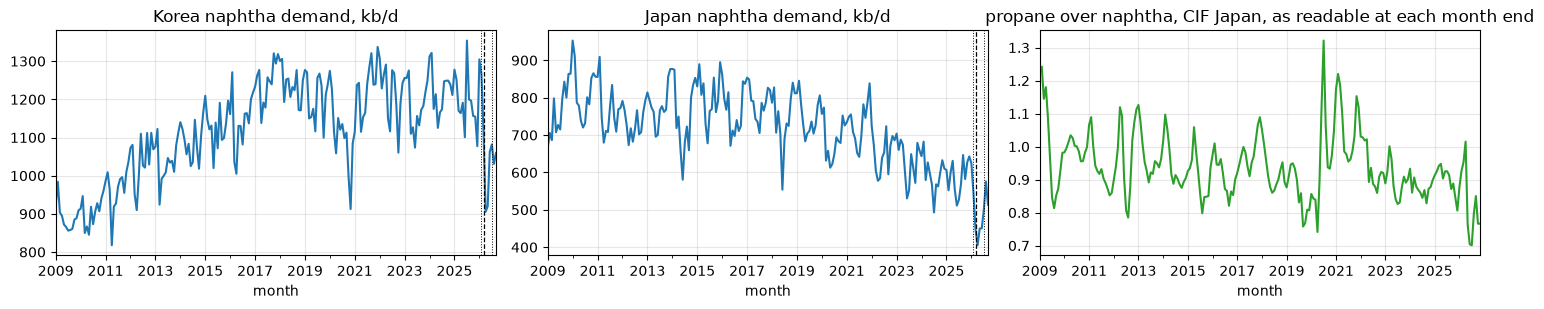

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, product in zip(axes, PRODUCTS):
    datasets[product]["demand"].dropna().plot(ax=ax, title={"naphtha_kr": "Korea naphtha demand, kb/d", "naphtha_jp": "Japan naphtha demand, kb/d"}[product])
    for date in c.KOREA_CUTS:
        ax.axvline(pd.Timestamp(date), color="k", lw=.7, ls=":")
    ax.axvline(pd.Timestamp(c.HORMUZ[0]), color="k", lw=.9, ls="--"); ax.set_xlabel("month")
datasets["naphtha_kr"]["propane_naphtha"].loc["2009":].plot(ax=axes[2], color="C2", title="propane over naphtha, CIF Japan, as readable at each month end")
axes[2].set_xlabel("month")
plt.tight_layout();

**What this dataset is and is not.**

- Every driver value was published by the month end of its row, under release-calendar lags that a real download confirms are not too short.
- It is **not** a vintage dataset. Values are today's, including later revisions: the customs months are the definitive figures, not the preliminary ones a forecaster saw first.
- Lags are conventions rounded up to a month end, so the customs ratio is used up to a few days later than it could be. The bias is towards a harder test for the model, not an easier one.
- Nothing was filled or removed. Missing values stay missing; XGBoost handles them natively.

## 9. Customs codes and unit values

The feature the model gets is the ratio of two prices Japan actually paid at its border: the CIF unit value of propane over that of naphtha, both in yen per tonne, so the ratio has no unit and needs no exchange rate.

In [27]:
# the codes: the months each one carries in the raw files, and its unit
codes = sql.query("""
    SELECT split_part(series, ' / ', 1) AS code, split_part(series, ' / ', 3) AS unit,
           MIN(obs_date) AS first_month, MAX(obs_date) AS last_month
    FROM latest WHERE file = 'KR_JP_naphtha/customs.csv' GROUP BY 1, 2 ORDER BY 1
""")
codes.insert(1, "product", codes["code"].map(c.CUSTOMS))
codes

,code,product,unit,first_month,last_month
0,271011181,naphtha,KG,2009-01-01,2011-12-01
1,271012181,naphtha,KG,2012-01-01,2026-09-01
2,271112000,propane,MT,2016-01-01,2026-09-01
3,271112010,propane,MT,2012-08-01,2015-12-01
4,271112020,propane,MT,2009-01-01,2015-12-01
5,271113010,butane,MT,2009-01-01,2026-09-01
6,271113020,butane,MT,2009-01-01,2026-09-01


,min,25%,50%,75%,max
propane / naphtha,0.70,0.88,0.93,0.99,1.32


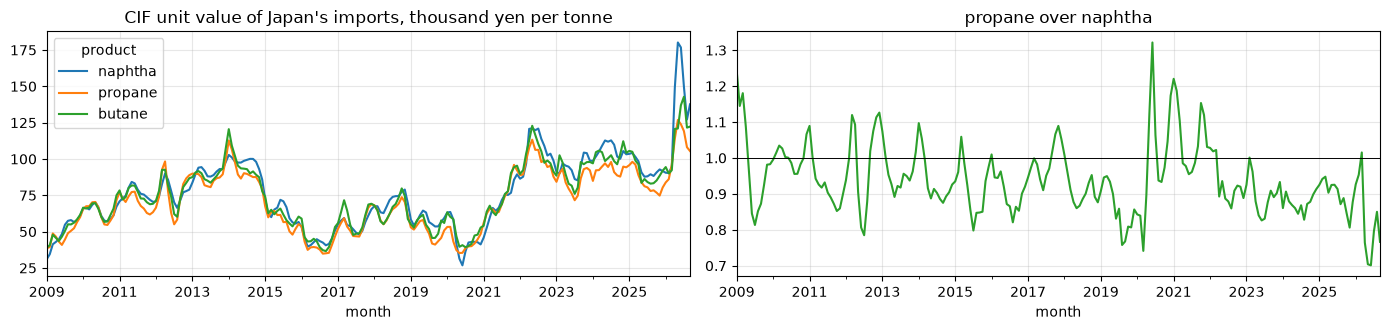

In [28]:
# unit values, thousand yen per tonne, and the ratio the model gets
uv = sql.query("SELECT period_end, product, SUM(kyen) / SUM(tonnes) AS kyen_per_t FROM imports GROUP BY 1, 2").pivot(index="period_end", columns="product", values="kyen_per_t")
uv["propane / naphtha"] = uv["propane"] / uv["naphtha"]
# the same numbers the predictors table holds
stored = sql.query("SELECT period_end, value FROM predictors WHERE product = 'naphtha_kr' AND variable = 'propane_naphtha'").set_index("period_end")["value"]
assert (uv["propane / naphtha"] - stored.reindex(uv.index)).abs().max() < 1e-12
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
uv[["naphtha", "propane", "butane"]].plot(ax=axes[0], title="CIF unit value of Japan's imports, thousand yen per tonne"); axes[0].set_xlabel("month")
uv["propane / naphtha"].plot(ax=axes[1], color="C2", title="propane over naphtha")
axes[1].axhline(1, color="k", lw=.7); axes[1].set_xlabel("month")
plt.tight_layout();
uv["propane / naphtha"].describe()[["min", "25%", "50%", "75%", "max"]].to_frame().T

In [29]:
# descriptive only: the Gulf's share of Japan's naphtha and propane imports, %, around the closure of Hormuz
gulf = sql.query("SELECT period_end, variable, value FROM predictors WHERE product = 'naphtha_jp' AND variable LIKE 'gulf%'").pivot(index="period_end", columns="variable", values="value")
print(gulf.groupby(gulf.index.year).mean().T.round(0))  # yearly means
gulf.loc["2025-10":].T.round(0)

period_end    2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
variable                                                                                                                
gulf_naphtha 55.00 49.00 48.00 49.00 36.00 42.00 48.00 55.00 56.00 59.00 55.00 53.00 57.00 62.00 74.00 74.00 74.00 47.00
gulf_propane 87.00 89.00 92.00 88.00 80.00 75.00 64.00 55.00 33.00 23.00  9.00  8.00  6.00  7.00  4.00  3.00  1.00  0.00


period_end,2025-10-31,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31,2026-09-30
variable,,,,,,,,,,,,
gulf_naphtha,71.00,72.00,72.00,70.00,75.00,73.00,29.00,9.00,17.00,48.00,50.00,52.00
gulf_propane,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
